### Goals

- gather models trained on different folds with different setups
- aggregate over diffferent folds, and seeds if applicable
- with each model, predict the entire training dataset (through the different folds) 
- evaluate


In [1]:
import sys
import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import os 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm
import pickle

import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [2]:
import sys
sys.path.append('../')
from evaluate import compute_and_log_metrics


### Examples of how to filter wandb runs:

example_filters = {


    "group" : "17/5 single-bi-trimodal",
    "config.image_encoder.use": True,
    "config.batch_size": {'$gt': 10}, #Greater than
    "config.batch_size": {'$lte': 10}, #Less than or equal
    
	"$and": [{
		'created_at': {
			"$lt": '2022-03-09T10',
			"$gt": '2022-03-07T17'
		}
	}],
    
    "$or": [{
        'config.train_examples_per_class': {
            "$gt": '200',
        }
    },
        {
        'config.train_examples_per_class': {
            "$lt": '200',
        }
    }
    ]
    
    
}

In [3]:
# Define the filter criteria
filter_criteria = {

    "group" : "6/6 cosine regularization with freezing",

}


In [4]:
models = utils.get_wandb_runs(filter_criteria)

print(f'models: {len(models)}')

models: 72


In [42]:
'''
In some cases, the wandb API filtering doesn't work;
If I get 0 models returned, I need to 
    1. remove the problematic filter
    2. get all the runs
    3. filter manually as below
'''
#Example:
#selected_models = [model for model in models  if model['config']['train dst size'] > 10000]  
#print(len(selected_models))
#models = selected_models

"\nIn some cases, the wandb API filtering doesn't work;\nIf I get 0 models returned, I need to \n    1. remove the problematic filter\n    2. get all the runs\n    3. filter manually as below\n"

In [5]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
n_classes = 12


In [6]:
for model_dict in tqdm.tqdm(models):

    metrics, preds = utils.load_model_and_predict(model_dict, n_classes, device)
    model_dict['predictions'] = preds
    model_dict['metrics'] = metrics
    
    #This is just to get rid of wandb objects that are un-picklable wtf
    model_dict['summary'] = dict(model_dict['summary'])
    model_dict['summary']['_wandb'] = dict(model_dict['summary']['_wandb'])

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 72/72 [12:04<00:00, 10.06s/it]


In [7]:
filename = 'regularization_results_9_6.pickle'
with open(filename, 'wb') as handle:
    pickle.dump(models, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [134]:
with open(filename, 'rb') as handle:
    models_loaded = pickle.load(handle)

In [8]:
print(len(models))
#print(len(models_loaded))
#print(len((models + models_loaded)))

72


In [140]:
#models = models + models_loaded

In [11]:
#import importlib
#importlib.reload(utils)


In [12]:
hyperparams_values = utils.find_keys_with_multiple_values([model['config'] for model in models])

In [13]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v4/labels_55k.csv")
labels = labels.loc[labels['split_5'] != 4 ].reset_index(drop=True) #This is test split, not used 

targets = labels['driver'].map(LABEL_MAPPING).to_numpy()

#Get indices of dataset examples for each data split
indices_for_each_split = {}
for split in labels['split_5'].unique():
    indices_for_each_split[split] = labels.loc[labels['split_5'] == split].index.tolist()

In [14]:
def get_models_with_config(_models, target_config):
    
    def has_key_value_pair(d, target):
        if isinstance(d, dict) and isinstance(target, dict):
            for key, value in target.items():
                if key in d:
                    if isinstance(value, dict) and isinstance(d[key], dict):
                        if not has_key_value_pair(d[key], value):
                            return False
                    else:
                        if d[key] != value:
                            return False
                else:
                    return False
            return True
        return d == target
    
    models_with_this_config_combination = []
    for model in _models:
        skip_model = False
        for key in target_config.keys():
            if not has_key_value_pair(model['config'][key],target_config[key]):
            #if model['config'][key] != target_config[key]:
                skip_model = True
                break
        if skip_model:
            continue
        models_with_this_config_combination.append(model)
    
    return models_with_this_config_combination

In [15]:
exclude_keys = ['folds_to_split', 'seed']

combinations = utils.generate_combinations(hyperparams_values, exclude_keys)

In [21]:
pprint.pprint(hyperparams_values)

{'folds_to_split': {'mapping': [(('0', 'train'),
                                 ('1', 'train'),
                                 ('2', 'val'),
                                 ('3', 'train'),
                                 ('4', 'test')),
                                (('0', 'train'),
                                 ('1', 'val'),
                                 ('2', 'train'),
                                 ('3', 'train'),
                                 ('4', 'test')),
                                (('0', 'train'),
                                 ('1', 'train'),
                                 ('2', 'train'),
                                 ('3', 'val'),
                                 ('4', 'test')),
                                (('0', 'val'),
                                 ('1', 'train'),
                                 ('2', 'train'),
                                 ('3', 'train'),
                                 ('4', 'test'))]},
 'image_encoder': {'freeze

In [16]:
len(combinations)

18

In [17]:
from pprint import pformat

In [18]:
#This I need to do in case there is only 1 seed
hyperparams_values['seed'] = [420]

In [19]:

performance_per_configuration = {}

for combo in combinations:
    
    metrics_per_random_seed = []
    
    combo_str = ' '.join(pformat(combo, width=1).split())
    
    #Compute metrics per each random seed separately
    for seed in hyperparams_values['seed']:
        combo['seed'] = seed
        
        
        #Get all models that have the configuration setup 
        #(only difference is the excluded key 'folds_to_split')
        models_with_this_config = get_models_with_config(models, combo)
        if not models_with_this_config:
            #print(f'no models found with config: {combo}')
            continue
        #Init an empty array of the entire train+val size
        predictions_over_all_folds = np.full(labels.shape[0], np.nan)

        #Populate the array with the combined predictions of the 4-fold models
        #Each model is trained on 3/4 folds and predicts on the 4th fold
        for model in models_with_this_config:
            
            validation_split = int(utils.find_key_for_value(model['config']['folds_to_split']['mapping'], 'val'))
            indices_of_examples = indices_for_each_split[validation_split]
            predictions_over_all_folds[indices_of_examples] = model['predictions']

        #Now, predictions_over_all_folds should contain predictions over the entire training dataset
        # for a given configuration
        assert np.isnan(predictions_over_all_folds).any() == False  


        #compute metrics for this configuration
        metrics = compute_and_log_metrics(targets, predictions_over_all_folds, dataset_name='', log_to_wandb=False, losses=None)  
        metrics_per_random_seed.append(pd.DataFrame(metrics))


    if not metrics_per_random_seed:
        print("no metrics for: ", combo)
        continue


    # Concatenate DataFrames along a new axis
    concat_df = pd.concat(metrics_per_random_seed, keys=range(len(metrics_per_random_seed)))

    # Compute the mean along the new axis
    mean_df = concat_df.groupby(level=1).mean()

    # Compute the standard deviation along the new axis
    std_df = concat_df.groupby(level=1).std()   
    
    

    performance_per_configuration[combo_str] = {}
    performance_per_configuration[combo_str]['mean'] = mean_df
    performance_per_configuration[combo_str]['std'] = std_df



        

In [22]:
frozen_img_enc_models = {key:value for key, value in performance_per_configuration.items() if "'freeze_after': 6" in key}

models_50_per_class = {key:value for key, value in frozen_img_enc_models.items() if "'train_examples_per_class': 50}" in key}
models_100_per_class = {key:value for key, value in frozen_img_enc_models.items() if "'train_examples_per_class': 100}" in key}
models_500_per_class = {key:value for key,value in frozen_img_enc_models.items() if "'train_examples_per_class': 500}" in key}




In [23]:
import matplotlib.pyplot as plt


In [69]:
def plot_metrics(metrics):
    
    class_names = list(LABEL_MAPPING.keys())
    class_names.append('accuracy')
    stats = {}
    for model_name, model_stats in metrics.items():
        stats[model_name] = {}
        for cls in class_names:
            stats[model_name][cls] = {}
            stats[model_name][cls]['score'] = metrics[model_name]['mean'][cls]['f1-score']
            #stats[model_name][cls]['std'] = metrics[model_name]['std'][cls]['f1-score']

    # Initialize plot
    fig, ax = plt.subplots(figsize=(12, 6))

    # Set the width of the bars
    bar_width = 0.7/len(metrics)

    # Set positions of the bars on the x-axis
    index = np.arange(len(class_names))

    # Plot each model's data

    #for i, model in enumerate(stats.keys()):
    for i, model in enumerate(list(metrics.keys())): #only models with image
        scores = [stats[model][cls]['score'] for cls in class_names]
        #stds = [stats[model][cls]['std'] for cls in class_names]
        ax.bar(index + i * bar_width, scores, bar_width, label=model, capsize=5)

    # Set labels, title, and legend
    #ax.set_xlabel('Class')
    #ax.set_ylabel('Score')
    plt.ylim(bottom=0.2)
    plt.ylim(top=1)
    ax.set_xticks(index + bar_width / 2)
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.legend()

    # Show plot
    plt.tight_layout()
    plt.show()

In [57]:
#frozen_img_enc_models = {key:value for key, value in performance_per_configuration.items() if "'freeze_after': 6" in key}

temp_0 = {key:value['mean'] for key, value in performance_per_configuration.items() if "'regularization_temperature': 0," in key}
temp_002 = {key:value['mean'] for key, value in performance_per_configuration.items() if "'regularization_temperature': 0.02," in key}
temp_01 = {key:value['mean'] for key,value in performance_per_configuration.items() if "'regularization_temperature': 0.1," in key}




In [59]:
def average_dataframes(dfs_dict):
    # Get the list of dataframes
    dfs = list(dfs_dict.values())
    
    # Check if all dataframes have the same structure
    if not all(df.columns.equals(dfs[0].columns) for df in dfs):
        raise ValueError("All dataframes must have the same columns")
    if not all(df.index.equals(dfs[0].index) for df in dfs):
        raise ValueError("All dataframes must have the same index")
    
    # Calculate the average
    avg_df = pd.concat(dfs).groupby(level=0).mean()
    
    return avg_df

In [62]:
temp_0_avg = average_dataframes(temp_0)
temp_002_avg = average_dataframes(temp_002)
temp_01_avg = average_dataframes(temp_01)

In [65]:
avg = {
    'no regularization' : {'mean' : temp_0_avg} ,
    'temperature 0.02' : {'mean' : temp_002_avg} ,
    'temperature 0.1' : {'mean' : temp_01_avg} ,
    
}

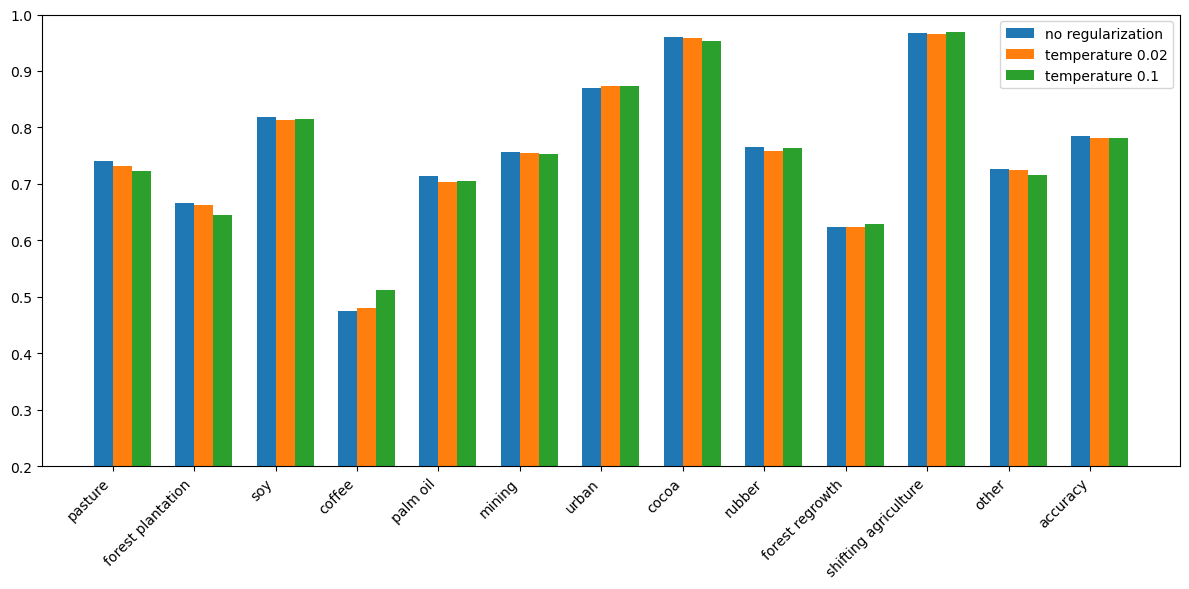

In [70]:
plot_metrics(avg)

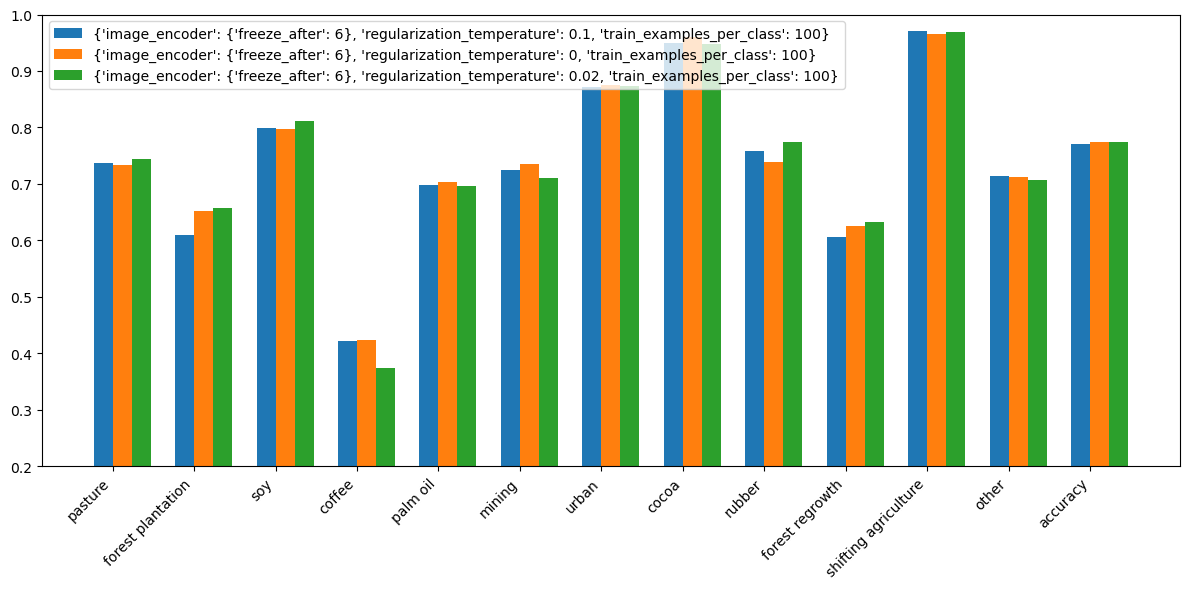

In [28]:
plot_metrics(models_100_per_class)

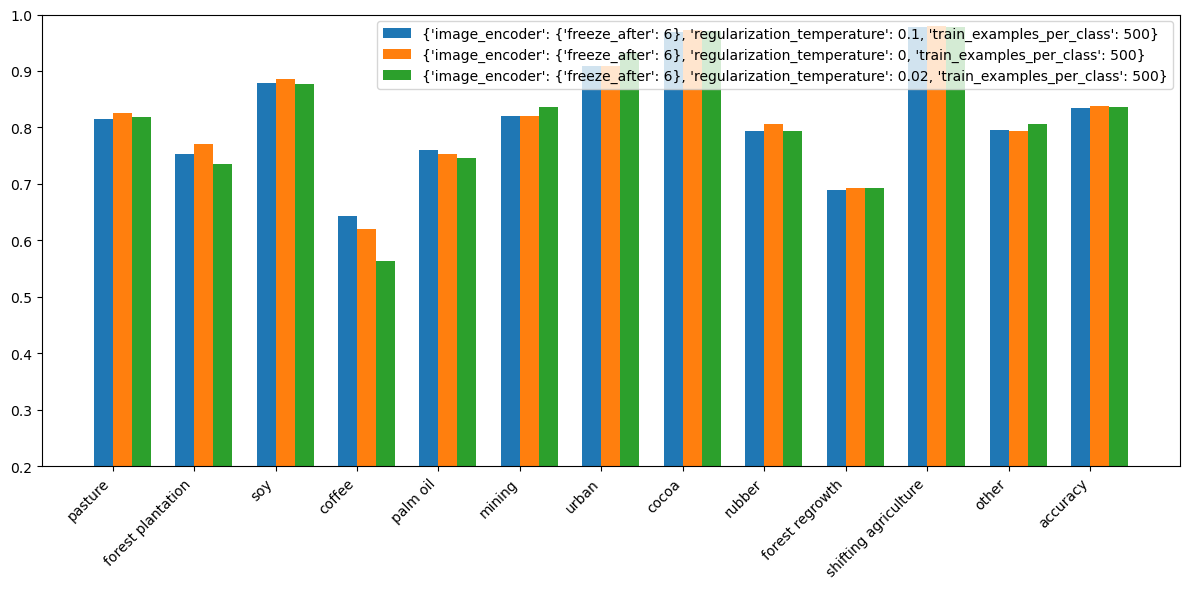

In [29]:
plot_metrics(models_500_per_class)

In [31]:
nonfrozen_img_enc_models = {key:value for key, value in performance_per_configuration.items() if "'freeze_after': 1000" in key}

nonfr_models_50_per_class = {key:value for key, value in nonfrozen_img_enc_models.items() if "'train_examples_per_class': 50}" in key}
nonfr_models_100_per_class = {key:value for key, value in nonfrozen_img_enc_models.items() if "'train_examples_per_class': 100}" in key}
nonfr_models_500_per_class = {key:value for key,value in nonfrozen_img_enc_models.items() if "'train_examples_per_class': 500}" in key}




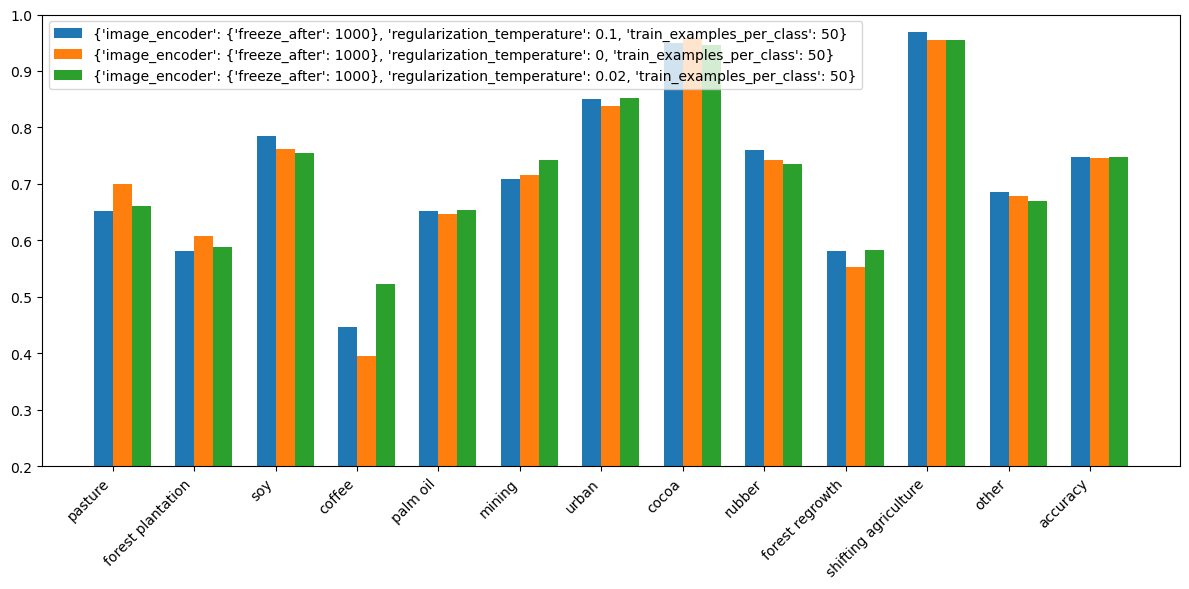

In [32]:
plot_metrics(nonfr_models_50_per_class)

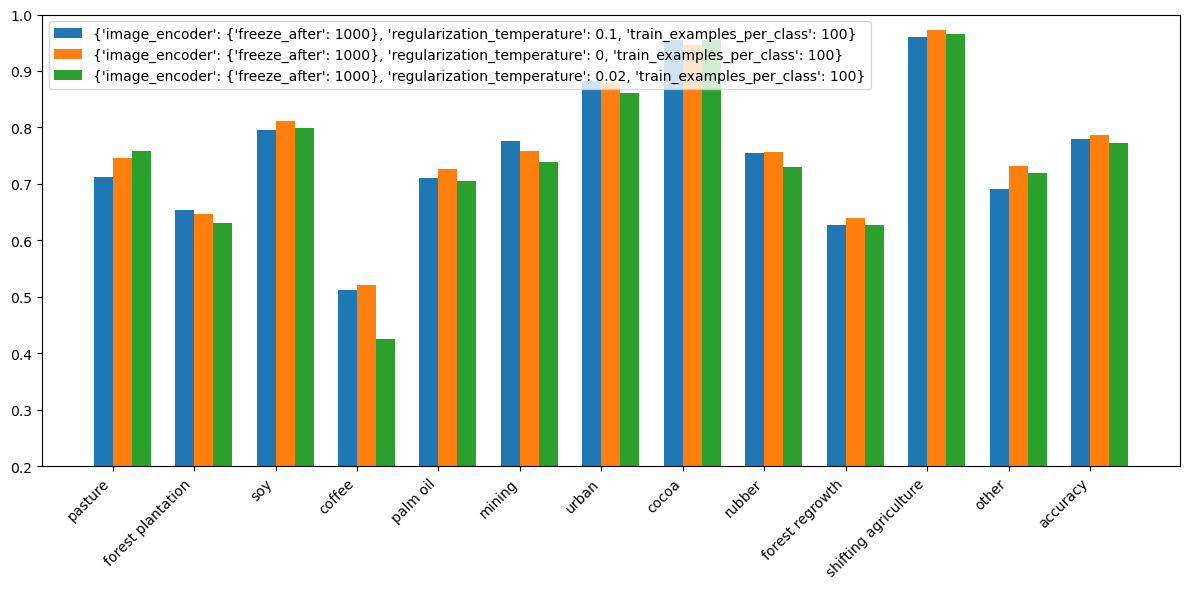

In [33]:
plot_metrics(nonfr_models_100_per_class)

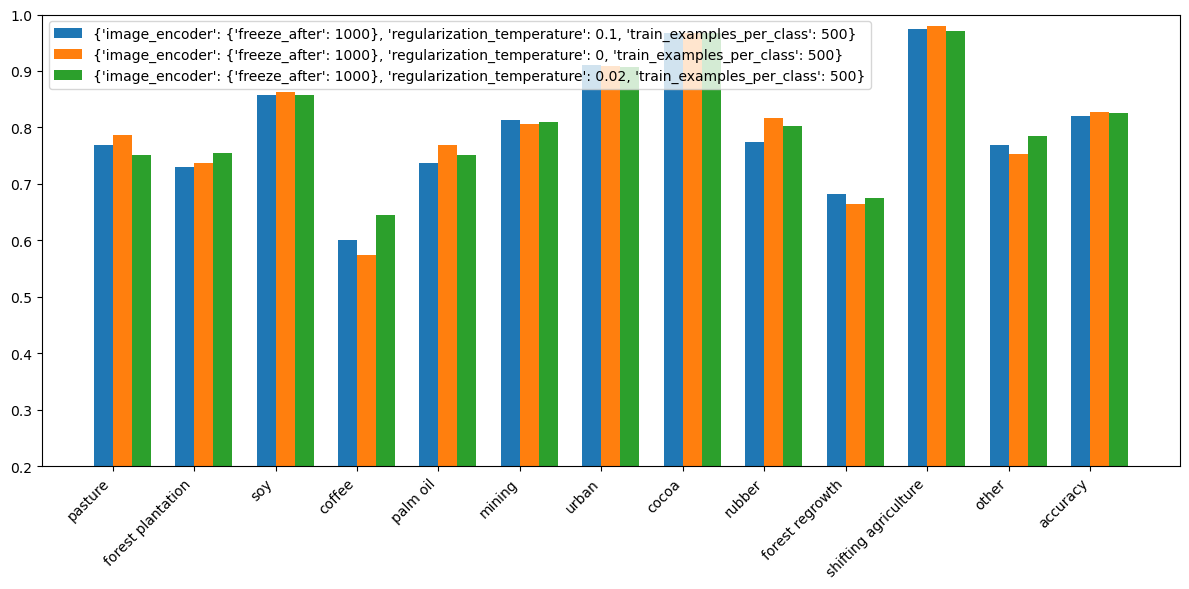

In [34]:
plot_metrics(nonfr_models_500_per_class)

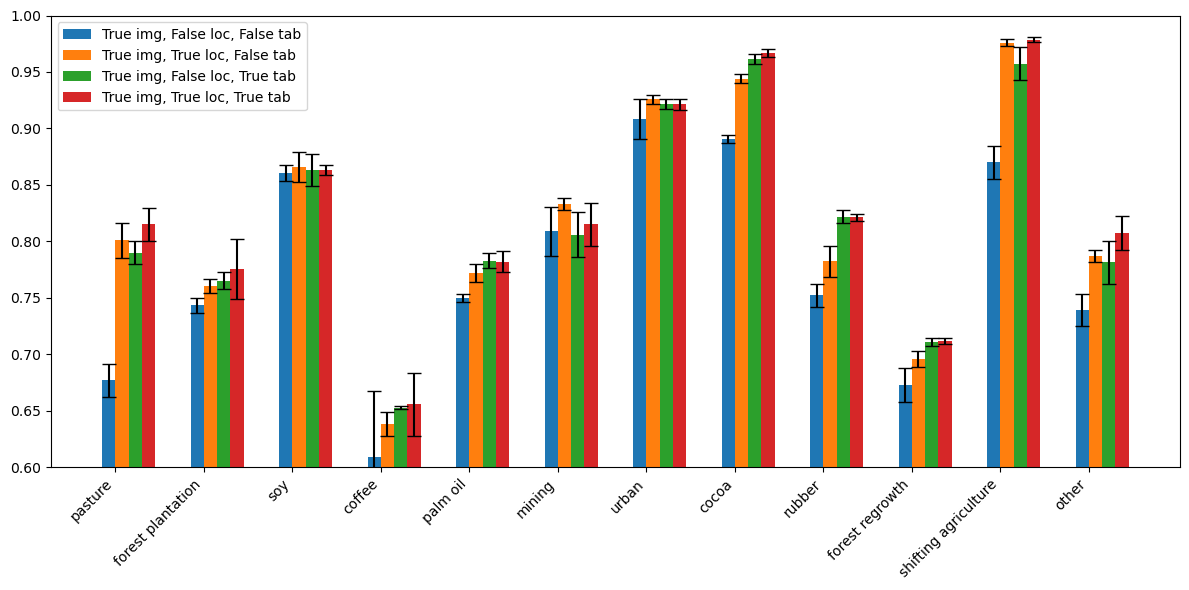

In [195]:
import matplotlib.pyplot as plt


# Extract classes and models
classes = list(stats['False img, False loc, True tab'].keys())
models = list(stats.keys())

# Initialize plot
fig, ax = plt.subplots(figsize=(12, 6))

# Set the width of the bars
bar_width = 0.15

# Set positions of the bars on the x-axis
index = np.arange(len(classes))

# Plot each model's data

#for i, model in enumerate(stats.keys()):
for i, model in enumerate(list(performance_per_configuration.keys())): #only models with image
    scores = [stats[model][cls]['score'] for cls in classes]
    stds = [stats[model][cls]['std'] for cls in classes]
    ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

# Set labels, title, and legend
#ax.set_xlabel('Class')
#ax.set_ylabel('Score')
plt.ylim(bottom=0.6)
plt.ylim(top=1)
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(classes, rotation=45, ha='right')
ax.legend()

# Show plot
plt.tight_layout()
plt.show()

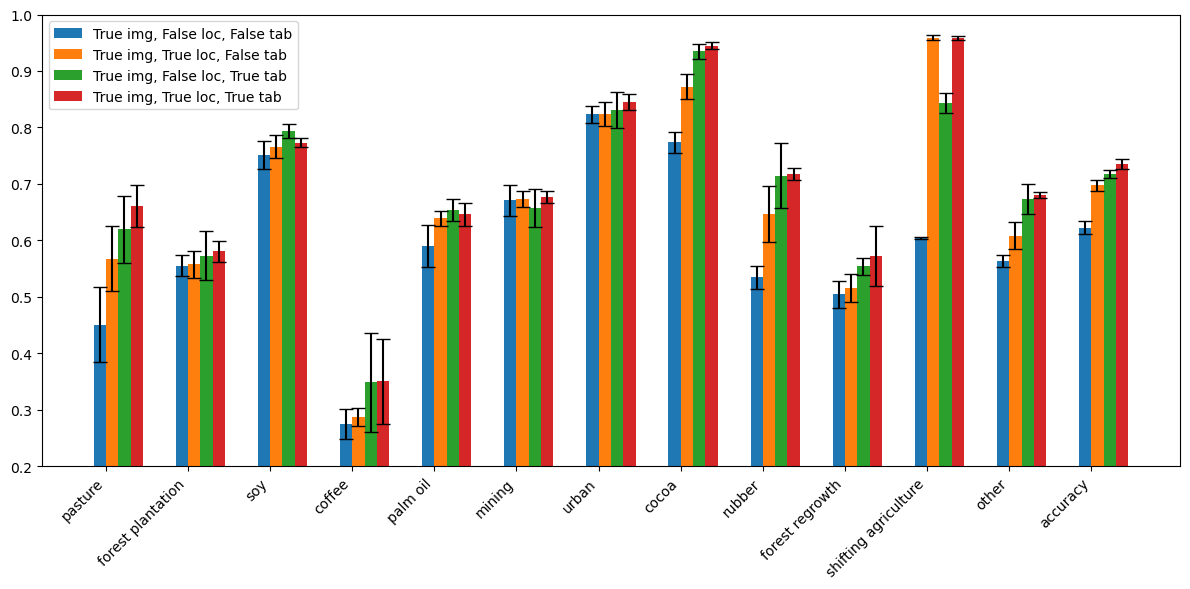

In [44]:
import matplotlib.pyplot as plt


# Extract classes and models
classes = list(stats['False img, False loc, True tab'].keys())
models = list(stats.keys())

# Initialize plot
fig, ax = plt.subplots(figsize=(12, 6))

# Set the width of the bars
bar_width = 0.15

# Set positions of the bars on the x-axis
index = np.arange(len(classes))

# Plot each model's data

#for i, model in enumerate(stats.keys()):
for i, model in enumerate(img_only_reordered): #only models with image
    scores = [stats[model][cls]['score'] for cls in classes]
    stds = [stats[model][cls]['std'] for cls in classes]
    ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

# Set labels, title, and legend
#ax.set_xlabel('Class')
#ax.set_ylabel('Score')
plt.ylim(bottom=0.2)
plt.ylim(top=1)
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(classes, rotation=45, ha='right')
ax.legend()

# Show plot
plt.tight_layout()
plt.show()

In [34]:
list(performance_per_configuration.keys())[0]

"{'image_encoder': {'freeze_after': 1000}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 100}"

In [38]:

performance_per_configuration["{'image_encoder': {'freeze_after': 1000}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 100}"]['mean']['accuracy']['f1-score']

0.6813160987074031

In [150]:
hyperparams_values

{'loc_encoder': {'use': [False, True]},
 'image_encoder': {'freeze_after': [1000, 'x', 6]},
 'folds_to_split': {'mapping': [(('0', 'train'),
    ('1', 'train'),
    ('2', 'train'),
    ('3', 'val'),
    ('4', 'test')),
   (('0', 'train'),
    ('1', 'train'),
    ('2', 'val'),
    ('3', 'train'),
    ('4', 'test')),
   (('0', 'val'),
    ('1', 'train'),
    ('2', 'train'),
    ('3', 'train'),
    ('4', 'test')),
   (('0', 'train'),
    ('1', 'val'),
    ('2', 'train'),
    ('3', 'train'),
    ('4', 'test'))]},
 'tabular_encoder': {'use': [False, True]},
 'train_examples_per_class': [100, 5000, 200, 10, 50, 500, 20],
 'seed': [420]}

In [37]:
pprint.pprint(hyperparams_values)

{'folds_to_split': {'mapping': [(('0', 'train'),
                                 ('1', 'train'),
                                 ('2', 'val'),
                                 ('3', 'train'),
                                 ('4', 'test')),
                                (('0', 'train'),
                                 ('1', 'val'),
                                 ('2', 'train'),
                                 ('3', 'train'),
                                 ('4', 'test')),
                                (('0', 'train'),
                                 ('1', 'train'),
                                 ('2', 'train'),
                                 ('3', 'val'),
                                 ('4', 'test')),
                                (('0', 'val'),
                                 ('1', 'train'),
                                 ('2', 'train'),
                                 ('3', 'train'),
                                 ('4', 'test'))]},
 'image_encoder': {'freeze

In [38]:
performance_per_configuration.keys()


dict_keys(["{'image_encoder': {'freeze_after': 1000}, 'regularization_temperature': 0.1, 'train_examples_per_class': 100}", "{'image_encoder': {'freeze_after': 1000}, 'regularization_temperature': 0, 'train_examples_per_class': 100}", "{'image_encoder': {'freeze_after': 1000}, 'regularization_temperature': 0.02, 'train_examples_per_class': 100}", "{'image_encoder': {'freeze_after': 1000}, 'regularization_temperature': 0.1, 'train_examples_per_class': 50}", "{'image_encoder': {'freeze_after': 1000}, 'regularization_temperature': 0, 'train_examples_per_class': 50}", "{'image_encoder': {'freeze_after': 1000}, 'regularization_temperature': 0.02, 'train_examples_per_class': 50}", "{'image_encoder': {'freeze_after': 1000}, 'regularization_temperature': 0.1, 'train_examples_per_class': 500}", "{'image_encoder': {'freeze_after': 1000}, 'regularization_temperature': 0, 'train_examples_per_class': 500}", "{'image_encoder': {'freeze_after': 1000}, 'regularization_temperature': 0.02, 'train_exampl

In [40]:
data_to_plot = {}

data_to_plot['reg_0'] = [key for key in performance_per_configuration.keys() if 
           ("{'image_encoder': {'freeze_after': 1000}" in key and
            "'regularization_temperature': 0," in key 
           )
           ]

data_to_plot['reg_002'] = [key for key in performance_per_configuration.keys() if 
           ("{'image_encoder': {'freeze_after': 1000}" in key and
            "'regularization_temperature': 0.02," in key 
           )
           ]

data_to_plot['reg_01'] = [key for key in performance_per_configuration.keys() if 
           ("{'image_encoder': {'freeze_after': 1000}" in key and
            "'regularization_temperature': 0.1," in key 
           )
           ]


data_to_plot['reg_0_freeze'] = [key for key in performance_per_configuration.keys() if 
           ("{'image_encoder': {'freeze_after': 6}" in key and
            "'regularization_temperature': 0," in key 
           )
           ]

data_to_plot['reg_002_freeze'] = [key for key in performance_per_configuration.keys() if 
           ("{'image_encoder': {'freeze_after': 6}" in key and
            "'regularization_temperature': 0.02," in key 
           )
           ]

data_to_plot['reg_01_freeze'] = [key for key in performance_per_configuration.keys() if 
           ("{'image_encoder': {'freeze_after': 6}" in key and
            "'regularization_temperature': 0.1," in key 
           )
           ]


In [42]:
import ast

In [43]:
for model_group, model_keys in data_to_plot.items():
    print(model_group)
    n_examples = []
    accuracy = []
    f1_score = []
    for key in model_keys:
        n_examples.append( int(ast.literal_eval(key)['train_examples_per_class']) )
        accuracy.append(performance_per_configuration[key]['mean']['accuracy']['f1-score'])
        f1_score.append(performance_per_configuration[key]['mean']['macro avg']['f1-score'])
        
    data = sorted(zip(n_examples, accuracy, f1_score))
    # Unzip the sorted data
    sorted_n_examples, sorted_accuracy, sorted_f1_score = zip(*data)
        
    data_to_plot[model_group] = {}
    data_to_plot[model_group]['x'] = sorted_n_examples
    data_to_plot[model_group]['y'] = sorted_accuracy
    data_to_plot[model_group]['f1'] = sorted_f1_score
    

reg_0
reg_002
reg_01
reg_0_freeze
reg_002_freeze
reg_01_freeze


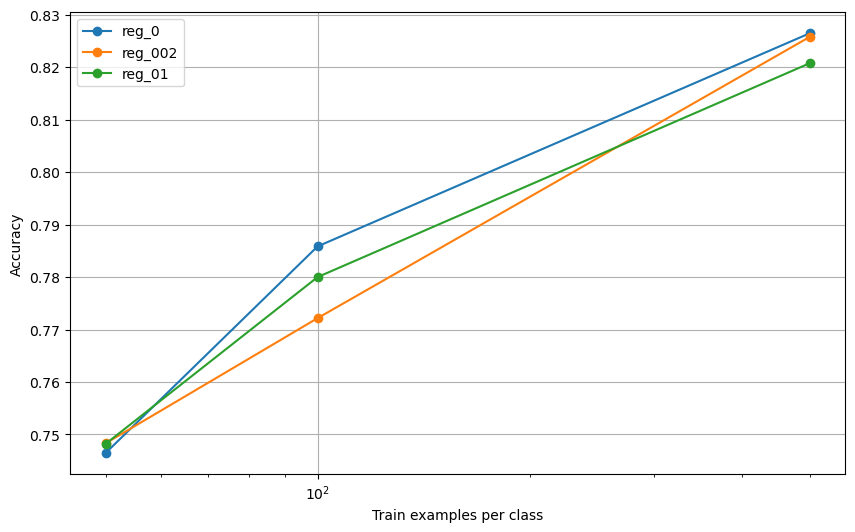

In [45]:

# Plotting
plt.figure(figsize=(10, 6))
for key, value in data_to_plot.items():
    if "freeze" in key:
        continue
    #label = key.replace('fr_1000', '')
    plt.plot(value['x'], value['y'], marker='o', label=key)
plt.xlabel('Train examples per class')
plt.ylabel('Accuracy')
#plt.title('Evaluation of additional modalities')
plt.grid(True)
plt.xscale('log')
plt.legend()
plt.show()

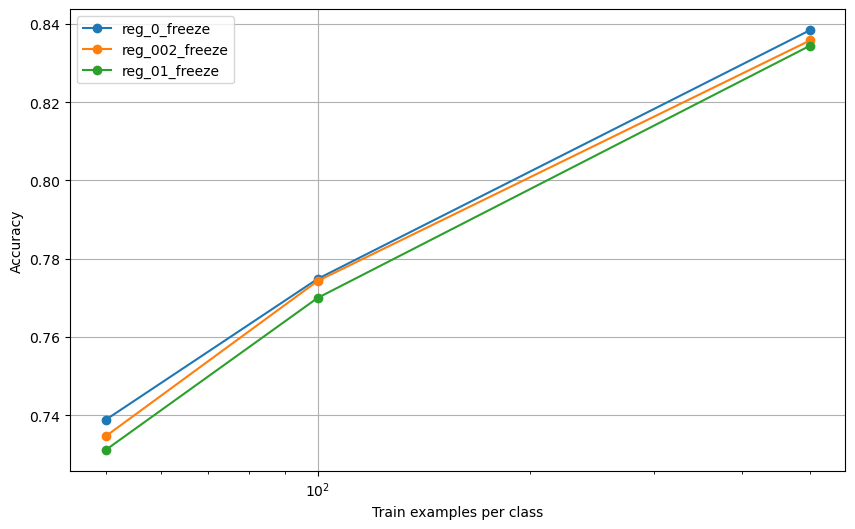

In [46]:

# Plotting
plt.figure(figsize=(10, 6))
for key, value in data_to_plot.items():
    if not "freeze" in key:
        continue
    #label = key.replace('fr_1000', '')
    plt.plot(value['x'], value['y'], marker='o', label=key)
plt.xlabel('Train examples per class')
plt.ylabel('Accuracy')
#plt.title('Evaluation of additional modalities')
plt.grid(True)
plt.xscale('log')
plt.legend()
plt.show()

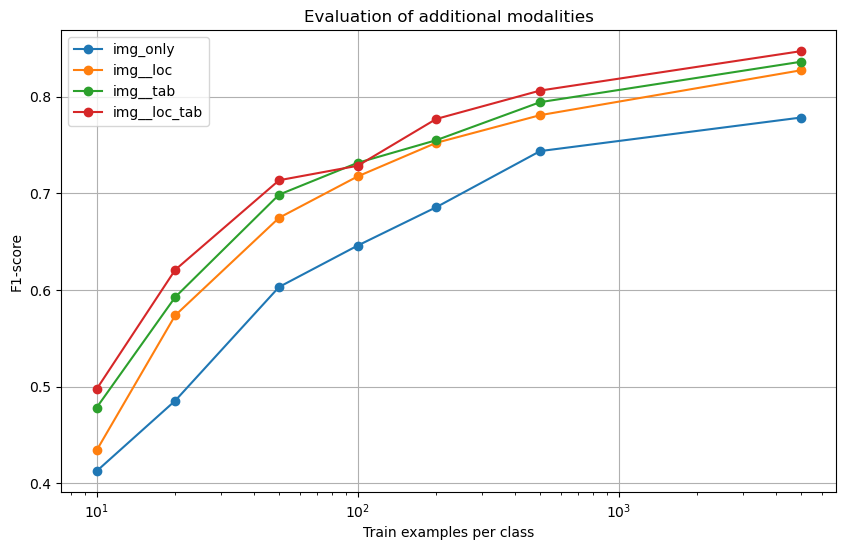

In [117]:

# Plotting
plt.figure(figsize=(10, 6))
for key, value in data_to_plot.items():
    if "6" in key:
        continue
    label = key.replace('fr_1000', '')
    plt.plot(value['x'], value['f1'], marker='o', label=label)
plt.xlabel('Train examples per class')
plt.ylabel('F1-score')
plt.title('Evaluation of additional modalities')
plt.grid(True)
plt.xscale('log')
plt.legend()
plt.show()

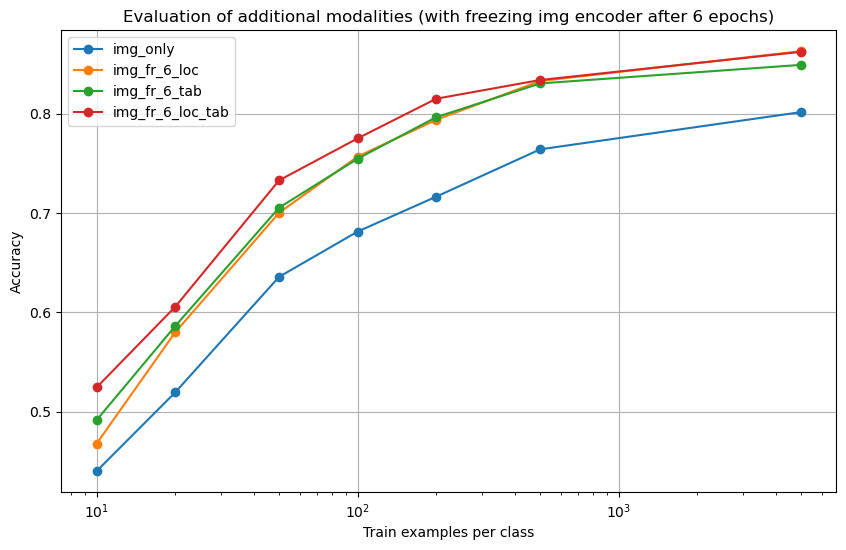

In [108]:

# Plotting
plt.figure(figsize=(10, 6))
for key, value in data_to_plot.items():
    if "1000" in key:
        continue
    plt.plot(value['x'], value['y'], marker='o', label=key)
plt.xlabel('Train examples per class')
plt.ylabel('Accuracy')
plt.title('Evaluation of additional modalities (with freezing img encoder after 6 epochs)')
plt.grid(True)
plt.xscale('log')
plt.legend()
plt.show()

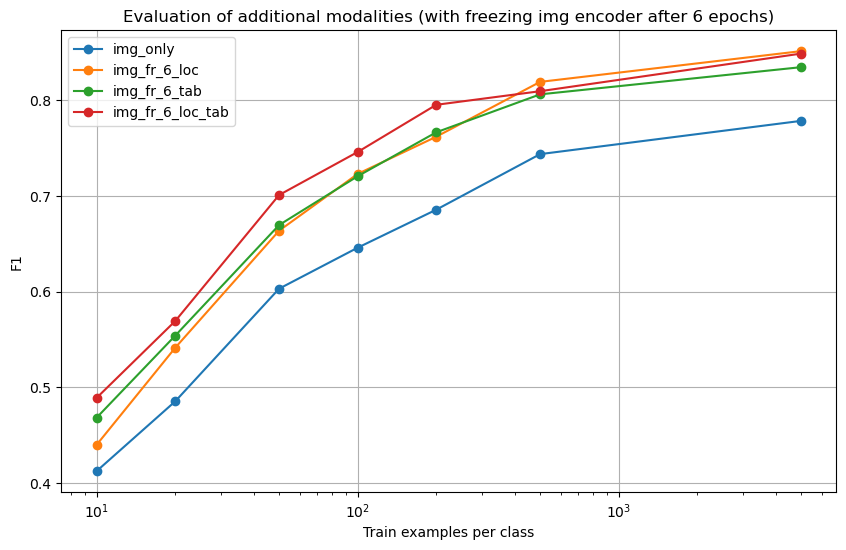

In [118]:

# Plotting
plt.figure(figsize=(10, 6))
for key, value in data_to_plot.items():
    if "1000" in key:
        continue
    plt.plot(value['x'], value['f1'], marker='o', label=key)
plt.xlabel('Train examples per class')
plt.ylabel('F1')
plt.title('Evaluation of additional modalities (with freezing img encoder after 6 epochs)')
plt.grid(True)
plt.xscale('log')
plt.legend()
plt.show()

In [96]:
data_to_plot.keys()

dict_keys(['img_only', 'img_fr_1000_loc', 'img_fr_1000_tab', 'img_fr_1000_loc_tab', 'img_fr_6_loc', 'img_fr_6_tab', 'img_fr_6_loc_tab'])

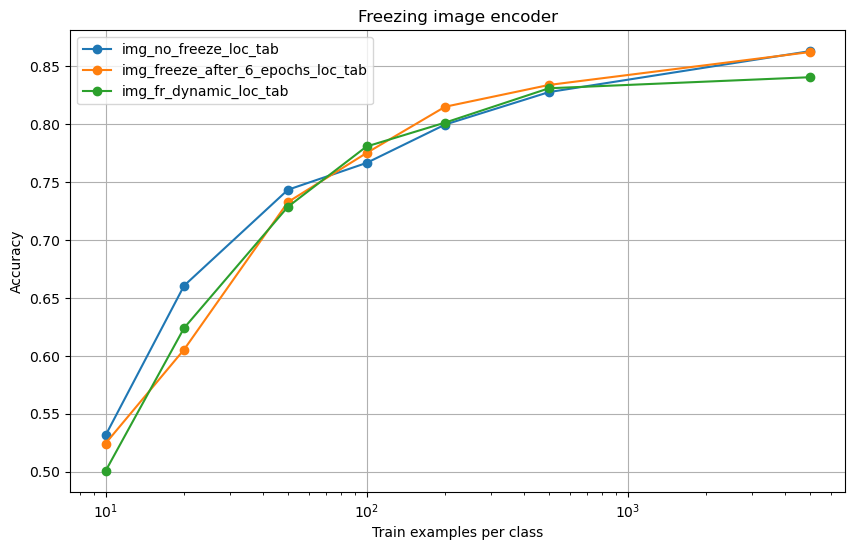

In [165]:
subset = ['img_fr_1000_loc_tab', 'img_fr_6_loc_tab', 'img_fr_dynamic_loc_tab']

# Plotting
plt.figure(figsize=(10, 6))
for key, value in data_to_plot.items():
    if key in subset:
        label = key.replace('fr_1000', 'no_freeze')
        label = label.replace('fr_6', 'freeze_after_6_epochs')
        plt.plot(value['x'], value['y'], marker='o', label=label)
plt.xlabel('Train examples per class')
plt.ylabel('Accuracy')
plt.title('Freezing image encoder')
plt.grid(True)
plt.xscale('log')
plt.legend()
plt.show()

In [119]:
print()

In [120]:
x = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/tabular/deduce_yearly.csv")

In [121]:
x.country.unique()

array(['Angola', 'Australia', 'Bahamas', 'Bangladesh', 'Belize', 'Benin',
       'Bhutan', 'Bolivia (Plurinational State of)', 'Brazil',
       'Brunei Darussalam', 'Burundi', 'Cambodia', 'Cameroon',
       'Central African Republic', 'China', 'Colombia', 'Costa Rica',
       'Cuba', "Côte d'Ivoire", 'Democratic Republic of the Congo',
       'Dominican Republic', 'Ecuador', 'El Salvador',
       'Equatorial Guinea', 'Ethiopia', 'Fiji', 'France', 'Gabon',
       'Ghana', 'Guatemala', 'Guinea', 'Guyana', 'Haiti', 'Honduras',
       'India', 'Indonesia', 'Jamaica', 'Kenya',
       "Lao People's Democratic Republic", 'Liberia', 'Madagascar',
       'Malaysia', 'Mozambique', 'Myanmar', 'Mexico', 'New Caledonia',
       'Nicaragua', 'Nigeria', 'Panama', 'Papua New Guinea', 'Paraguay',
       'Peru', 'Philippines', 'Puerto Rico', 'Congo', 'Rwanda',
       'Sierra Leone', 'Solomon Islands', 'Sri Lanka', 'South Sudan',
       'Suriname', 'United Republic of Tanzania', 'Thailand',
       'Timor

In [124]:
x.loc[x.country == 'Congo'].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,CongoCongoCongoCongoCongoCongoCongoCongoCongoC...,22.118453,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,CongoCongoCongoCongoCongoCongoCongoCongoCongoC...,33.584453,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",CongoCongoCongoCongoCongoCongoCongoCongoCongoC...,1.291305,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Leather,CongoCongoCongoCongoCongoCongoCongoCongoCongoC...,1.164129,PasturePasturePasturePasturePasturePasturePast...,44253
Natural rubber in primary forms,CongoCongoCongoCongoCongoCongoCongoCongoCongoC...,0.292184,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
Oil palm fruit,CongoCongoCongoCongoCongoCongoCongoCongoCongoC...,1.285253,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [215]:
x.loc[x.country == 'Bolivia (Plurinational State of)'].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,Bolivia (Plurinational State of)Bolivia (Pluri...,47.307818,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,Bolivia (Plurinational State of)Bolivia (Pluri...,0.095735,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",Bolivia (Plurinational State of)Bolivia (Pluri...,0.165045,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Unclassified),Bolivia (Plurinational State of)Bolivia (Pluri...,0.000029,Forest plantationForest plantationForest plant...,44253
Leather,Bolivia (Plurinational State of)Bolivia (Pluri...,2.489885,PasturePasturePasturePasturePasturePasturePast...,44253
Soya beans,Bolivia (Plurinational State of)Bolivia (Pluri...,16.963033,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [216]:
x.loc[x.country == 'Viet Nam'].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,Viet NamViet NamViet NamViet NamViet NamViet N...,7.397770,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,Viet NamViet NamViet NamViet NamViet NamViet N...,0.206834,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",Viet NamViet NamViet NamViet NamViet NamViet N...,4.145469,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Australian Blackwood),Viet NamViet NamViet NamViet NamViet NamViet N...,0.000010,Forest plantationForest plantationForest plant...,44253
Forest plantation (Unclassified),Viet NamViet NamViet NamViet NamViet NamViet N...,16.717140,Forest plantationForest plantationForest plant...,44253
Leather,Viet NamViet NamViet NamViet NamViet NamViet N...,0.389356,PasturePasturePasturePasturePasturePasturePast...,44253
Natural rubber in primary forms,Viet NamViet NamViet NamViet NamViet NamViet N...,25.573644,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
Oil palm fruit,Viet NamViet NamViet NamViet NamViet NamViet N...,0.001041,Oilseeds and oleaginous fruitsOilseeds and ole...,44253
Soya beans,Viet NamViet NamViet NamViet NamViet NamViet N...,0.302824,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [224]:
x.loc[x.country == 'Brazil'].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,75.068,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,0.348,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,0.400,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Birch),BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,0.000,Forest plantationForest plantationForest plant...,44253
Forest plantation (Unclassified),BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,1.963,Forest plantationForest plantationForest plant...,44253
Leather,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,3.951,PasturePasturePasturePasturePasturePasturePast...,44253
Natural rubber in primary forms,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,0.095,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
Oil palm fruit,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,0.033,Oilseeds and oleaginous fruitsOilseeds and ole...,44253
Soya beans,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,9.018,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [217]:
x.loc[x.country == 'Peru'].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,51.613482,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,4.507773,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,6.456404,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Unclassified),PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,0.207253,Forest plantationForest plantationForest plant...,44253
Leather,PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,2.716499,PasturePasturePasturePasturePasturePasturePast...,44253
Oil palm fruit,PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,4.940126,Oilseeds and oleaginous fruitsOilseeds and ole...,44253
Soya beans,PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,0.021388,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [12]:
x.loc[x.country == "Côte d'Ivoire"].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,Côte d'IvoireCôte d'IvoireCôte d'IvoireCôte d'...,2.373868,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,Côte d'IvoireCôte d'IvoireCôte d'IvoireCôte d'...,29.411639,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",Côte d'IvoireCôte d'IvoireCôte d'IvoireCôte d'...,9.434511,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Leather,Côte d'IvoireCôte d'IvoireCôte d'IvoireCôte d'...,0.124940,PasturePasturePasturePasturePasturePasturePast...,44253
Natural rubber in primary forms,Côte d'IvoireCôte d'IvoireCôte d'IvoireCôte d'...,4.476891,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
Oil palm fruit,Côte d'IvoireCôte d'IvoireCôte d'IvoireCôte d'...,2.857013,Oilseeds and oleaginous fruitsOilseeds and ole...,44253
Soya beans,Côte d'IvoireCôte d'IvoireCôte d'IvoireCôte d'...,0.001687,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [48]:
xx = x.groupby(['Commodity', 'country']).sum().reset_index()


In [50]:
xx.Commodity.unique()

array(['Cattle meat', 'Cocoa beans', 'Coffee, green',
       'Forest plantation (Alder)',
       'Forest plantation (Australian Blackwood)',
       'Forest plantation (Bamboo)', 'Forest plantation (Birch)',
       'Forest plantation (Broadleaf)', 'Forest plantation (Fir)',
       'Forest plantation (Mix of needleleaf and broadleaf)',
       'Forest plantation (Needleleaf)', 'Forest plantation (Padauk)',
       'Forest plantation (Pine)', 'Forest plantation (Sal)',
       'Forest plantation (Teak)', 'Forest plantation (Unclassified)',
       'Leather', 'Natural rubber in primary forms', 'Oil palm fruit',
       'Soya beans'], dtype=object)

In [32]:
xx.loc[xx.Commodity == 'Coffee, green'].sort_values(by='commodity attributed deforestation', ascending=False).head(10)

,Commodity,country,commodity attributed deforestation,Commodity group,Year
147,"Coffee, green",Honduras,15.609757,"Stimulant, spice and aromatic cropsStimulant, ...",44253
167,"Coffee, green",Puerto Rico,12.359904,"Stimulant, spice and aromatic cropsStimulant, ...",44253
131,"Coffee, green",Costa Rica,10.838481,"Stimulant, spice and aromatic cropsStimulant, ...",44253
173,"Coffee, green",Timor-Leste,10.650755,"Stimulant, spice and aromatic cropsStimulant, ...",44253
175,"Coffee, green",Uganda,9.816629,"Stimulant, spice and aromatic cropsStimulant, ...",44253
133,"Coffee, green",Côte d'Ivoire,9.434511,"Stimulant, spice and aromatic cropsStimulant, ...",44253
124,"Coffee, green",Burundi,9.431527,"Stimulant, spice and aromatic cropsStimulant, ...",44253
127,"Coffee, green",Central African Republic,7.596358,"Stimulant, spice and aromatic cropsStimulant, ...",44253
139,"Coffee, green",Ethiopia,7.429780,"Stimulant, spice and aromatic cropsStimulant, ...",44253
143,"Coffee, green",Guatemala,6.625385,"Stimulant, spice and aromatic cropsStimulant, ...",44253


In [51]:
xx.loc[xx.Commodity == 'Cocoa beans'].sort_values(by='commodity attributed deforestation', ascending=False).head(10)

,Commodity,country,commodity attributed deforestation,Commodity group,Year
77,Cocoa beans,Congo,33.584453,"Stimulant, spice and aromatic cropsStimulant, ...",44253
88,Cocoa beans,Ghana,33.072342,"Stimulant, spice and aromatic cropsStimulant, ...",44253
80,Cocoa beans,Côte d'Ivoire,29.411639,"Stimulant, spice and aromatic cropsStimulant, ...",44253
116,Cocoa beans,Vanuatu,24.193539,"Stimulant, spice and aromatic cropsStimulant, ...",44253
108,Cocoa beans,Solomon Islands,15.579048,"Stimulant, spice and aromatic cropsStimulant, ...",44253
74,Cocoa beans,Cameroon,13.065875,"Stimulant, spice and aromatic cropsStimulant, ...",44253
104,Cocoa beans,Papua New Guinea,12.252428,"Stimulant, spice and aromatic cropsStimulant, ...",44253
83,Cocoa beans,Ecuador,11.799691,"Stimulant, spice and aromatic cropsStimulant, ...",44253
97,Cocoa beans,Liberia,8.921441,"Stimulant, spice and aromatic cropsStimulant, ...",44253
107,Cocoa beans,Sierra Leone,8.195858,"Stimulant, spice and aromatic cropsStimulant, ...",44253


In [ ]:
xx.loc[xx.Commodity == 'Cocoa beans'].sort_values(by='commodity attributed deforestation', ascending=False).head(10)

In [54]:


xx.loc[xx.Commodity == 'Natural rubber in primary forms'].sort_values(by='commodity attributed deforestation', ascending=False).head(10)

,Commodity,country,commodity attributed deforestation,Commodity group,Year
348,Natural rubber in primary forms,Thailand,48.262893,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
350,Natural rubber in primary forms,Viet Nam,25.573644,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
323,Natural rubber in primary forms,Cambodia,23.219296,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
322,Natural rubber in primary forms,Brunei Darussalam,16.287893,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
339,Natural rubber in primary forms,Lao People's Democratic Republic,16.043715,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
341,Natural rubber in primary forms,Malaysia,15.731043,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
343,Natural rubber in primary forms,Myanmar,14.696409,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
338,Natural rubber in primary forms,Indonesia,12.185980,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
340,Natural rubber in primary forms,Liberia,5.415356,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
329,Natural rubber in primary forms,Côte d'Ivoire,4.476891,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253


In [55]:
x.loc[x.country == "Viet Nam"].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,Viet NamViet NamViet NamViet NamViet NamViet N...,7.397770,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,Viet NamViet NamViet NamViet NamViet NamViet N...,0.206834,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",Viet NamViet NamViet NamViet NamViet NamViet N...,4.145469,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Australian Blackwood),Viet NamViet NamViet NamViet NamViet NamViet N...,0.000010,Forest plantationForest plantationForest plant...,44253
Forest plantation (Unclassified),Viet NamViet NamViet NamViet NamViet NamViet N...,16.717140,Forest plantationForest plantationForest plant...,44253
Leather,Viet NamViet NamViet NamViet NamViet NamViet N...,0.389356,PasturePasturePasturePasturePasturePasturePast...,44253
Natural rubber in primary forms,Viet NamViet NamViet NamViet NamViet NamViet N...,25.573644,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
Oil palm fruit,Viet NamViet NamViet NamViet NamViet NamViet N...,0.001041,Oilseeds and oleaginous fruitsOilseeds and ole...,44253
Soya beans,Viet NamViet NamViet NamViet NamViet NamViet N...,0.302824,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [219]:
pd.set_option('display.float_format', lambda x: '%.3f' % x)

### Part 2


- aggregate models across folds

In [10]:
model_names = []

for i, model_dict in enumerate(models):
    _name = "".join(model_dict['name'].split(';')[:-1])
    #if model_dict['wandb_id'] in failed.keys():
    #    print(_name)
    model_names.append(_name)
    
model_names = list(set(model_names))

In [11]:
model_names

['True img yes loc reports_token tabular',
 'True img no loc no tabular',
 'False img yes loc no tabular',
 'False img no loc reports_token tabular',
 'True img no loc reports_token tabular',
 'False img yes loc reports_token tabular',
 'True img yes loc no tabular']

In [12]:
agg_models = {}

for model_name in model_names:
    agg_models[model_name] = [model_dict for model_dict in models if "".join(model_dict['name'].split(';')[:-1]) == model_name]


In [13]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v4/labels_55k.csv")

In [14]:
for model_name, model_group in agg_models.items():
    
    labels[model_name] = None
    
    for model_dict in model_group:

        val_dst = int(model_dict['name'].split('[')[-1].split(']')[0])
        try:
            
            labels.loc[labels['split'] == val_dst, model_name] = [inverse_label_mapping[i] for i in model_dict['predictions']]
        except KeyError:
            print(model_name)
            continue
    

In [15]:
#Excluding test set, keepin train + val
train_test = labels.loc[labels.split != 4]

In [16]:
columns_with_only_none = train_test.columns[train_test.isnull().all()].tolist()

In [17]:
df_filtered = train_test.drop(columns=columns_with_only_none)

In [18]:
df_filtered.columns

Index(['geometry', 'driver', 'sampleid', 'dataset', 'split', 'country',
       'True img yes loc reports_token tabular', 'True img no loc no tabular',
       'False img yes loc no tabular',
       'False img no loc reports_token tabular',
       'True img no loc reports_token tabular',
       'False img yes loc reports_token tabular',
       'True img yes loc no tabular'],
      dtype='object')

In [19]:
from sklearn.metrics import classification_report

In [20]:
'''cols_with_model_results = ['yes loc  reports_token tab transformer cls',
       'yes loc  reports_raw tab fc cls', 'yes loc  reports_token tab fc cls',
       'no loc  no tab transformer cls',
       'no loc  reports_token tab transformer cls',
       'no loc  reports_raw tab fc cls', 'yes loc  no tab transformer cls',
       'yes loc  no tab fc cls', 'no loc  reports_token tab fc cls',
       'no loc  no tab fc cls']'''


cols_with_model_results = ['True img yes loc reports_token tabular', 'True img no loc no tabular',
       'False img yes loc no tabular',
       'False img no loc reports_token tabular',
       'True img no loc reports_token tabular',
       'False img yes loc reports_token tabular',
       'True img yes loc no tabular']



In [21]:
for col in cols_with_model_results:
    metrics = pd.DataFrame(classification_report(df_filtered['driver'], df_filtered[col], output_dict=True))
    print(col, '; accuracy:', metrics['accuracy']['f1-score'])


True img yes loc reports_token tabular ; accuracy: 0.8849441157133465
True img no loc no tabular ; accuracy: 0.8269514158108322
False img yes loc no tabular ; accuracy: 0.625042508331633


/home/jan/miniconda3/envs/torch/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/jan/miniconda3/envs/torch/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/jan/miniconda3/envs/torch/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


False img no loc reports_token tabular ; accuracy: 0.45337686186492554
True img no loc reports_token tabular ; accuracy: 0.8743793783581582
False img yes loc reports_token tabular ; accuracy: 0.6299848103561632
True img yes loc no tabular ; accuracy: 0.8807499603255572


In [164]:
#Filter examples where base model is incorrect and tri-modal model is correct

fixed = df_filtered.loc[
    (df_filtered['no loc  no tab transformer cls'] != df_filtered['driver'])
     & 
    (df_filtered['yes loc  reports_token tab transformer cls'] == df_filtered['driver'])
     ]

In [163]:
#Filter examples where base model is correct and tri-modal model is not

incorrect = df_filtered.loc[
    (df_filtered['no loc  no tab transformer cls'] == df_filtered['driver'])
     & 
    (df_filtered['yes loc  reports_token tab transformer cls'] != df_filtered['driver'])
     ]

In [177]:
classes, fixed_counts  = np.unique(fixed.driver, return_counts=True)

In [178]:
classes, incorrect_counts = np.unique(incorrect.driver, return_counts=True)

In [179]:
incorrect_counts

array([  4,  29, 228, 392, 250, 183, 296,  92, 164,  18, 188, 114])

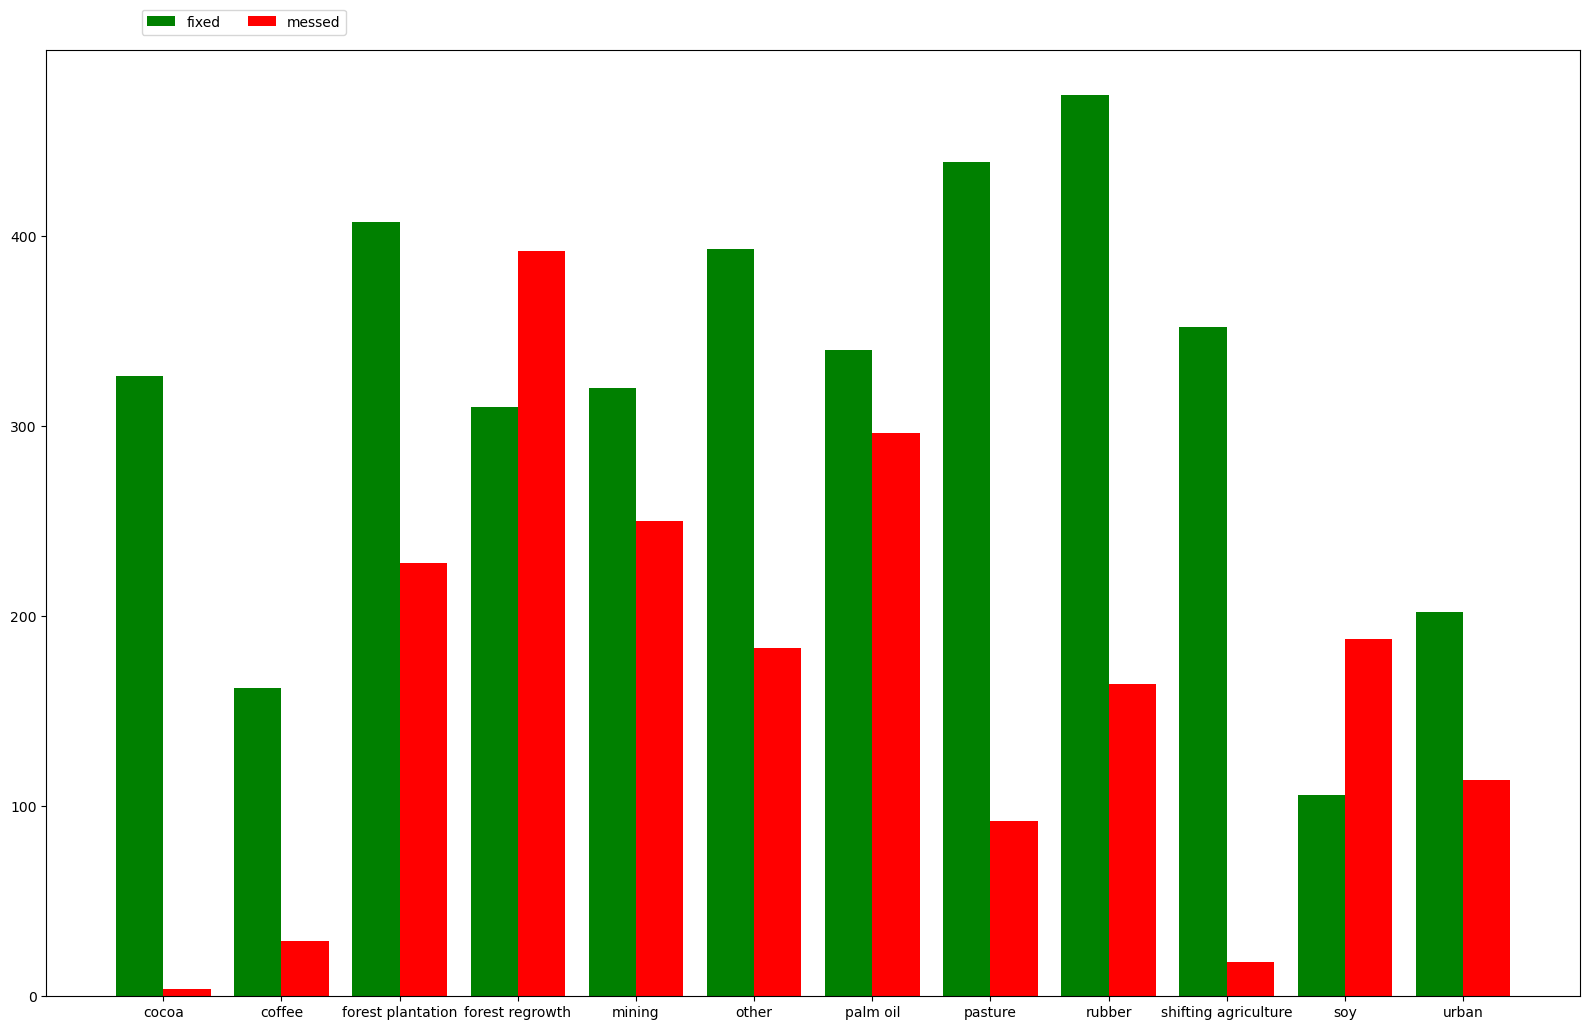

In [180]:

_x = np.arange(len(classes))  # the label locations
fig, ax = plt.subplots(1,figsize=(16,10))

ax.bar(_x-0.2, fixed_counts, width=0.4, color='green', align='center', label='fixed')
ax.bar(_x+0.2, incorrect_counts, width=0.4, color='red', align='center', label='messed')
plt.xticks(_x, classes) 
plt.tight_layout()
plt.legend(bbox_to_anchor=(0.2, 1.05), ncol=5)
plt.show()

In [182]:

cls, base_model_preds = np.unique(df_filtered['no loc  no tab transformer cls'], return_counts=True)
cls, trimodal_preds = np.unique(df_filtered['yes loc  reports_token tab transformer cls'], return_counts=True)

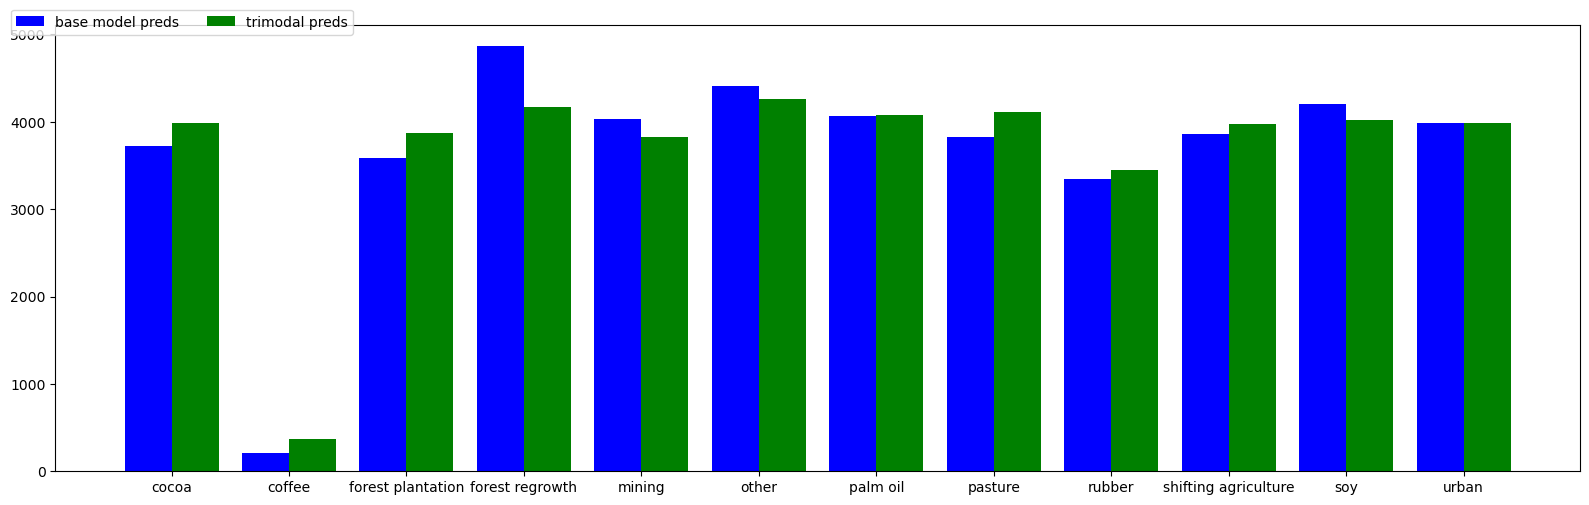

In [187]:

_x = np.arange(len(cls))  # the label locations
fig, ax = plt.subplots(1,figsize=(16,5))

ax.bar(_x-0.2, base_model_preds, width=0.4, color='blue', align='center', label='base model preds')
ax.bar(_x+0.2, trimodal_preds, width=0.4, color='green', align='center', label='trimodal preds')
plt.xticks(_x, classes) 
plt.tight_layout()
plt.legend(bbox_to_anchor=(0.2, 1.05), ncol=5)
plt.show()

In [198]:

    
incorrect_dict = dict(zip(*np.unique(incorrect.country, return_counts=True)))
fixed_dict = dict(zip(*np.unique(fixed.country, return_counts=True)))

In [201]:
for country in labels.country.unique():
    try:
        print(country)
        print('fixed: ',fixed_dict[country] , 'messed: ', incorrect_dict[country])
    except KeyError:
        continue

Ecuador
fixed:  245 messed:  25
Côte d'Ivoire
fixed:  21 messed:  2
Ghana
fixed:  77 messed:  57
Colombia
fixed:  26 messed:  13
Brazil
fixed:  1011 messed:  655
Viet Nam
fixed:  230 messed:  42
Indonesia
fixed:  1133 messed:  890
Malaysia
fixed:  101 messed:  69
Mexico
fixed:  13 messed:  2
Cuba
fixed:  11 messed:  7
Bolivia (Plurinational State of)
fixed:  5 messed:  2
United States of America
Australia
fixed:  3 messed:  3
Guatemala
fixed:  3 messed:  3
Philippines
fixed:  15 messed:  2
Lao People's Democratic Republic
fixed:  45 messed:  23
Peru
fixed:  56 messed:  1
Guyana
fixed:  18 messed:  3
India
fixed:  5 messed:  1
Democratic Republic of the Congo
fixed:  255 messed:  42
Papua New Guinea
fixed:  13 messed:  7
Gabon
fixed:  24 messed:  4
Uganda
fixed:  6 messed:  3
Venezuela (Bolivarian Republic of)
fixed:  14 messed:  3
Sri Lanka
Myanmar
fixed:  33 messed:  32
Suriname
Ethiopia
fixed:  2 messed:  1
Liberia
fixed:  8 messed:  1
Thailand
fixed:  178 messed:  18
Bahamas
Kenya
f

In [23]:

df_filtered

,geometry,driver,sampleid,dataset,split,country,True img yes loc reports_token tabular,True img no loc no tabular,False img yes loc no tabular,False img no loc reports_token tabular,True img no loc reports_token tabular,False img yes loc reports_token tabular,True img yes loc no tabular
1,POINT (-3.252726923505843 6.05540773743447),cocoa,30005848,cocoa.csv,1,Côte d'Ivoire,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
2,POINT (-1.8324904593128795 6.046244921563979),cocoa,30005875,cocoa.csv,1,Ghana,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
6,POINT (-0.7054641038565277 5.624755391523431),cocoa,30007242,cocoa.csv,0,Ghana,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
7,POINT (-79.5647662448441 -1.9379355564808602),cocoa,110003683,cocoa_ecuador.csv,0,Ecuador,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
9,POINT (-0.6413243925703949 6.412757556385085),cocoa,30004120,cocoa.csv,2,Ghana,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
...,...,...,...,...,...,...,...,...,...,...,...,...,...
55298,POINT (76.66305108549047 10.758438413532348),urban,100002981,worldcover.csv,1,India,urban,urban,urban,urban,urban,urban,urban
55299,POINT (106.68137671728651 -6.334442760971974),urban,100009782,worldcover.csv,1,Indonesia,urban,urban,other,other,urban,other,urban
55300,POINT (-35.322382484061244 -5.749666958458276),urban,10427227,mapbiomas.csv,2,Brazil,urban,urban,urban,pasture,urban,pasture,urban
55301,POINT (101.5439344788162 3.154945653990399),urban,100004466,worldcover.csv,1,Malaysia,urban,urban,urban,urban,urban,urban,urban


## Plot and check examples of (i) where the tri-modal helped and (ii) where it made it worse

In [24]:
df_filtered['True img yes loc reports_token tabular'] 

1        cocoa
2        cocoa
6        cocoa
7        cocoa
9        cocoa
         ...  
55298    urban
55299    urban
55300    urban
55301    urban
55302    urban
Name: True img yes loc reports_token tabular, Length: 44109, dtype: object

In [25]:

incorrect = df_filtered.loc[

    (df_filtered['True img yes loc reports_token tabular'] != df_filtered['driver'])
     ]

In [28]:
np.unique(incorrect['driver'], return_counts=True)

(array(['cocoa', 'coffee', 'forest plantation', 'forest regrowth',
        'mining', 'other', 'palm oil', 'pasture', 'rubber',
        'shifting agriculture', 'soy', 'urban'], dtype=object),
 array([ 24, 114, 819, 887, 560, 628, 734, 362, 494,  45, 215, 193]))